## 1. Selección del dataset

AI4I 2020 (UCI) permite estudiar la predicción binaria de `Machine failure` para mantenimiento predictivo. Sus temperaturas, velocidad, torque y desgaste justifican un problema análogo al mantenimiento de maquinaria agropecuaria. Son datos industriales sintéticos: este encuadre didáctico no demuestra validez operativa agrícola.

Fuente: [página UCI](https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset). Descarga oficial: https://archive.ics.uci.edu/static/public/601/ai4i+2020+predictive+maintenance+dataset.zip.

Licencia: CC BY 4.0. Cita: Matzka, S. (2020). AI4I 2020 Predictive Maintenance Dataset. UCI Machine Learning Repository. https://doi.org/10.24432/C5HS5C.

Notebook generado desde Python; los resultados ya están incorporados. Para volver a ejecutar las celdas, usar el entorno del proyecto desde su raíz.

In [1]:
from pathlib import Path
from pprint import pprint

import polars as pl

from agrofail import config, eda
from agrofail.load import load_dataset

raw = load_dataset()
pprint({'shape': raw.shape, 'target': config.TARGET_COLUMN})

{'shape': (10000, 14), 'target': 'Machine failure'}

## 2. Análisis exploratorio inicial (EDA)

Se inspeccionan dimensiones, tipos, valores faltantes (nulos y NaN), estadísticas descriptivas y balance de clases. Los histogramas muestran las distribuciones de sensores; el mapa de calor resume correlaciones de Pearson. Correlación no implica causalidad ni utilidad predictiva. Esta exploración no ajusta parámetros de transformación.

{'row_count': 10000,
 'column_count': 14,
 'columns': {'UDI': {'dtype': 'Int64', 'missing_count': 0},
             'Product ID': {'dtype': 'String', 'missing_count': 0},
             'Type': {'dtype': 'String', 'missing_count': 0},
             'Air temperature [K]': {'dtype': 'Float64', 'missing_count': 0},
             'Process temperature [K]': {'dtype': 'Float64',
                                         'missing_count': 0},
             'Rotational speed [rpm]': {'dtype': 'Int64', 'missing_count': 0},
             'Torque [Nm]': {'dtype': 'Float64', 'missing_count': 0},
             'Tool wear [min]': {'dtype': 'Int64', 'missing_count': 0},
             'Machine failure': {'dtype': 'Int64', 'missing_count': 0},
             'TWF': {'dtype': 'Int64', 'missing_count': 0},
             'HDF': {'dtype': 'Int64', 'missing_count': 0},
             'PWF': {'dtype': 'Int64', 'missing_count': 0},
             'OSF': {'dtype': 'Int64', 'missing_count': 0},
             'RNF': {'dtype': 'Int

column,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
str,f64,f64,f64,f64,f64
"""Air temperature [K]""",1.0,0.876107,0.02267,-0.013778,0.013853
"""Process temperature [K]""",0.876107,1.0,0.019277,-0.014061,0.013488
"""Rotational speed [rpm]""",0.02267,0.019277,1.0,-0.875027,0.000223
"""Torque [Nm]""",-0.013778,-0.014061,-0.875027,1.0,-0.003093
"""Tool wear [min]""",0.013853,0.013488,0.000223,-0.003093,1.0


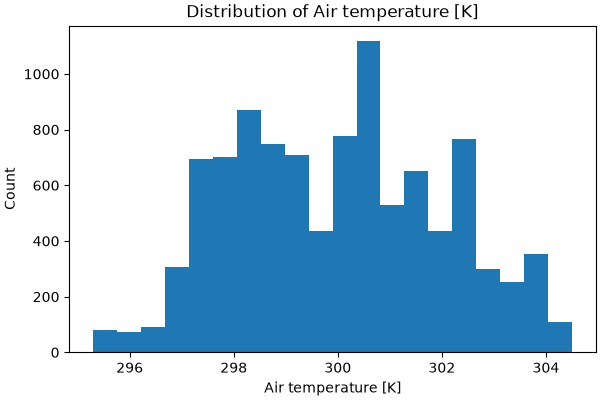

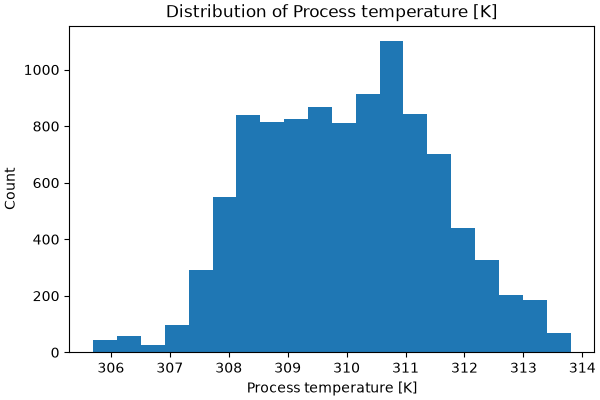

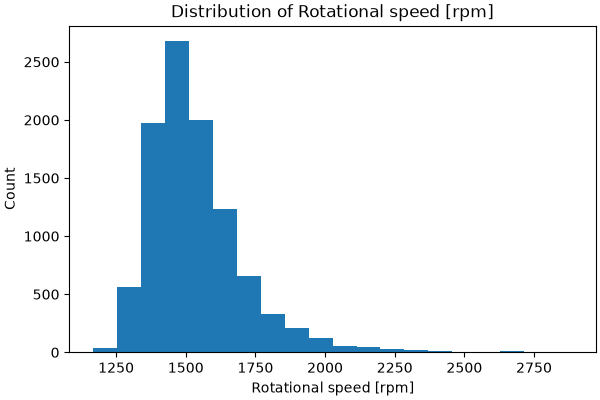

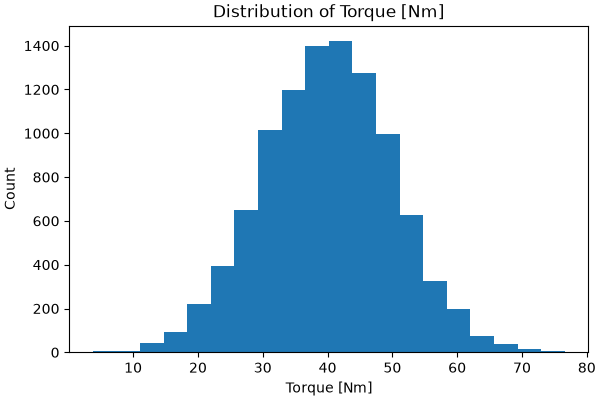

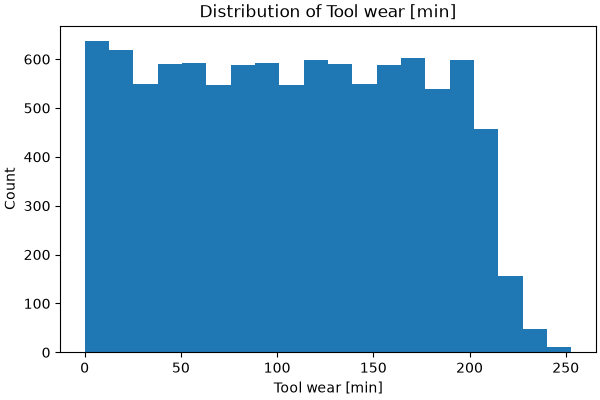

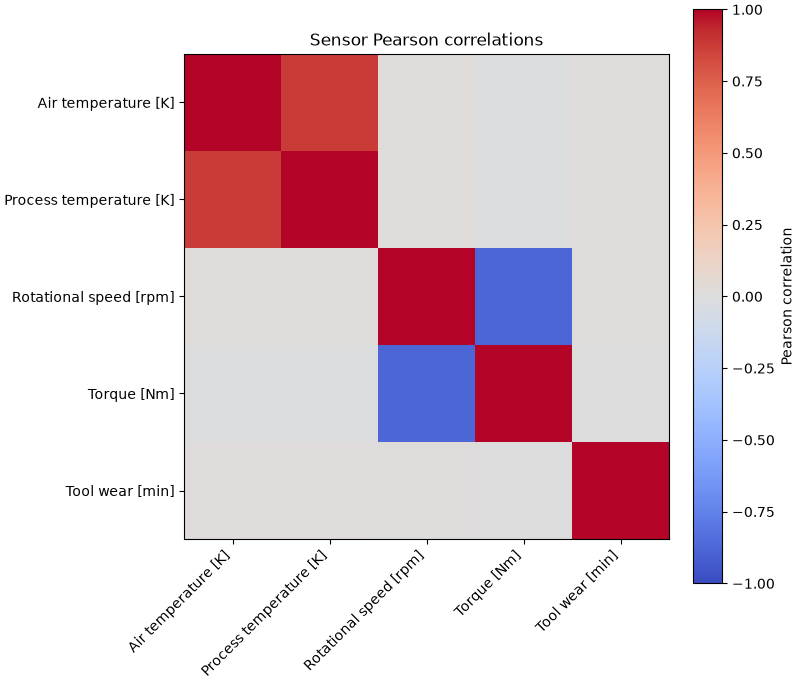

In [2]:
from IPython.display import Image, display

pprint(eda.summarise(raw))
print(eda.correlation_matrix(raw))
figure_dir = Path('notebooks/figures')
figures = eda.plot_distributions(raw, figure_dir)
figures.append(eda.plot_correlation_heatmap(raw, figure_dir))
for path in figures:
    display(Image(filename=str(path)))

## 3. Limpieza de datos

Se eliminan duplicados exactos conservando la primera fila y se descartan filas con nulos en sensores, tipo u objetivo, sin imputación. Esta política no trata NaN como nulo: los sensores no finitos fallan en la transformación. Los valores atípicos se reportan mediante límites IQR (1,5 veces el rango intercuartílico), pero no se eliminan ni recortan: pueden indicar fallas. Los conteos por sensor pueden solaparse; se informa también el total de filas. La pérdida por faltantes debe revisarse por posible sesgo de selección.

In [3]:
from agrofail.clean import clean, detect_outliers, drop_duplicates

cleaned = clean(raw)
pprint({'input_rows': raw.height,
        'duplicates_removed': raw.height - drop_duplicates(raw).height,
        'rows_dropped_missing': drop_duplicates(raw).height - cleaned.height,
        'remaining_rows': cleaned.height,
        'outlier_rows_retained': detect_outliers(cleaned).height,
        'outliers_by_sensor': {name: detect_outliers(cleaned, [name]).height
                               for name in config.NUMERIC_COLUMNS}})

{'input_rows': 10000,
 'duplicates_removed': 0,
 'rows_dropped_missing': 0,
 'remaining_rows': 10000,
 'outlier_rows_retained': 459,
 'outliers_by_sensor': {'Air temperature [K]': 0,
                        'Process temperature [K]': 0,
                        'Rotational speed [rpm]': 418,
                        'Torque [Nm]': 69,
                        'Tool wear [min]': 0}}

## 4. Transformaciones básicas

Aunque la división se presenta en la sección 6, se realiza ANTES del ajuste. Se ajustan categorías y escalas solo con entrenamiento y se aplican al test sin reajuste. One-hot evita imponer un orden a `Type`; categorías nuevas se representan con ceros. StandardScaler centra y escala sensores según media y desviación de entrenamiento. Se muestran filas antes/después y parámetros aprendidos. Se excluyen identificadores, modos de falla y columnas no configuradas mediante selección de dominio sobre las columnas originales (justificada en la sección 5); el objetivo permanece como etiqueta.

In [4]:
from agrofail.features import apply_encode_and_scale, fit_encode_and_scale
from agrofail.select import select_features
from agrofail.split import split

train_raw, test_raw = split(cleaned)
train_selected = select_features(train_raw)
test_selected = select_features(test_raw)
transformer = fit_encode_and_scale(train_selected)
train_encoded = apply_encode_and_scale(train_selected, transformer)
test_encoded = apply_encode_and_scale(test_selected, transformer)
print(train_raw.head())
print(train_encoded.head())
print(test_encoded.head())
pprint({'sensor_means': transformer.scaler.mean_.tolist(),
        'sensor_scales': transformer.scaler.scale_.tolist(),
        'categories': transformer.encoder.categories_[0].tolist(),
        'removed_columns': [c for c in train_raw.columns
                            if c not in transformer.output_columns]})

UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
i64,str,str,f64,f64,i64,f64,i64,i64,i64,i64,i64,i64,i64
4059,"""M18918""","""M""",302.0,310.9,1456,47.2,54,0,0,0,0,0,0
1222,"""M16081""","""M""",297.0,308.3,1399,46.4,132,0,0,0,0,0,1
6896,"""M21755""","""M""",301.0,311.6,1357,45.6,137,0,0,0,0,0,0
9864,"""L57043""","""L""",298.9,309.8,1411,56.3,84,0,0,0,0,0,0
8712,"""L55891""","""L""",297.1,308.5,1733,28.7,50,0,0,0,0,0,0


Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Type_H,Type_L,Type_M,Machine failure
f64,f64,f64,f64,f64,f64,f64,f64,i64
0.998914,0.604282,-0.460607,0.718305,-0.843997,0.0,0.0,1.0,0
-1.505194,-1.15326,-0.775574,0.638456,0.382263,0.0,0.0,1.0,0
0.498092,1.077466,-1.007654,0.558607,0.46087,0.0,0.0,1.0,0
-0.553633,-0.139294,-0.709265,1.626586,-0.372359,0.0,1.0,0.0,0
-1.455112,-1.018064,1.070019,-1.128202,-0.906882,0.0,1.0,0.0,0


Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Type_H,Type_L,Type_M,Machine failure
f64,f64,f64,f64,f64,f64,f64,f64,i64
0.247681,-0.139294,-1.073963,2.265378,0.71241,0.0,1.0,0.0,0
1.85031,1.618248,-0.145641,0.009646,0.429427,0.0,1.0,0.0,0
1.249324,0.94227,0.108543,-0.239882,1.592802,0.0,1.0,0.0,0
-2.206344,-2.505215,-0.167744,-0.419543,-0.74967,1.0,0.0,0.0,0
0.247681,-0.004098,-1.002129,2.035812,-0.089376,1.0,0.0,0.0,0


{'sensor_means': [300.00545, 310.0060625, 1539.356875, 40.0033625, 107.685],
 'sensor_scales': [1.996719258558899,
                   1.4793392092734339,
                   180.9716311061885,
                   10.018919350089297,
                   63.608026419627265],
 'categories': ['H', 'L', 'M'],
 'removed_columns': ['UDI',
                     'Product ID',
                     'Type',
                     'TWF',
                     'HDF',
                     'PWF',
                     'OSF',
                     'RNF']}

## 5. Selección de variables

La tabla presenta la política de dominio y sus razones: conservar sensores y tipo; excluir identificadores y modos de falla para evitar fuga de información. El objetivo se conserva como etiqueta, nunca como predictor. La varianza y correlación en entrenamiento son diagnósticos, no reglas automáticas de eliminación. No se inventan variables derivadas ni importancias de modelos.

In [5]:
from agrofail.select import selection_rationale

rationale = selection_rationale(train_raw)
decisions = pl.DataFrame([{'column': name, 'decision': decision, 'reason': reason}
    for decision, reasons in [('kept', rationale.kept), ('dropped', rationale.dropped)]
    for name, reason in reasons.items()])
with pl.Config(tbl_rows=-1, tbl_cols=-1, fmt_str_lengths=200):
    display(decisions)
pprint({'variances': rationale.variances, 'correlations': rationale.correlations,
        'notes': rationale.notes})
train, test = train_encoded, test_encoded

column,decision,reason
str,str,str
"""Air temperature [K]""","""kept""","""Ambient thermal conditions affect cooling and operating temperature."""
"""Process temperature [K]""","""kept""","""Process temperature describes operating heat, distinct from ambient conditions."""
"""Rotational speed [rpm]""","""kept""","""Rotational speed describes the machine operating regime."""
"""Torque [Nm]""","""kept""","""Torque measures mechanical load and stress."""
"""Tool wear [min]""","""kept""","""Tool wear measures accumulated degradation."""
"""Type""","""kept""","""Machine Type represents product quality; encode using training rows only."""
"""Machine failure""","""kept""","""Prediction target retained as a label, not a predictor."""
"""UDI""","""dropped""","""Excluded identifier: record/product identity is not a physical predictor."""
"""Product ID""","""dropped""","""Excluded identifier: record/product identity is not a physical predictor."""


{'variances': {'Air temperature [K]': 3.986887797499996,
               'Process temperature [K]': 2.1884444960937466,
               'Rotational speed [rpm]': 32750.731265234375,
               'Torque [Nm]': 100.37874494359374,
               'Tool wear [min]': 4045.9810249999987},
 'correlations': {('Air temperature [K]', 'Process temperature [K]'): 0.8761095803968669,
                  ('Air temperature [K]', 'Rotational speed [rpm]'): 0.02484071241479611,
                  ('Air temperature [K]', 'Torque [Nm]'): -0.014754125459234862,
                  ('Air temperature [K]', 'Tool wear [min]'): 0.009925933720146425,
                  ('Process temperature [K]', 'Rotational speed [rpm]'): 0.017960843978471013,
                  ('Process temperature [K]', 'Torque [Nm]'): -0.012488572743878523,
                  ('Process temperature [K]', 'Tool wear [min]'): 0.012417762132257596,
                  ('Rotational speed [rpm]', 'Torque [Nm]'): -0.8741017354050321,
                  ('

## 6. División del dataset

Se utiliza una división estratificada con fracción de prueba 0.2 y semilla 42. Las proporciones se conservan sujetas al redondeo de filas. La separación previa al ajuste protege la evaluación; ambas particiones comparten el esquema aprendido en entrenamiento. Los modelos se entrenan a continuación.

In [6]:
for name, frame in [('train', train), ('test', test)]:
    counts = eda.summarise(frame)['class_balance']
    pprint({name: {'shape': frame.shape, 'class_counts': counts,
                   'class_proportions': {label: count / frame.height
                                         for label, count in counts.items()}}})

{'train': {'shape': (8000, 9),
           'class_counts': {0: 7729, 1: 271},
           'class_proportions': {0: 0.966125, 1: 0.033875}},
 'test': {'shape': (2000, 9),
          'class_counts': {0: 1932, 1: 68},
          'class_proportions': {0: 0.966, 1: 0.034}}}

## 7. Modelos entrenados

Se ajustan tres líneas base sin optimización: regresión logística (máximo 1000 iteraciones), Random Forest (100 árboles) y árbol de decisión (profundidad 4). No se ponderan las clases. Todos usan la misma partición y los mismos sensores y categorías, sin identificadores ni modos de falla. La regresión incluye StandardScaler ajustado solo con entrenamiento; los árboles no requieren escala. La escala externa ya aprendida se conserva para reproducir la preparación. La semilla fija permite reproducibilidad, no demuestra estabilidad.

In [7]:
from agrofail.models import train_models

target = config.TARGET_COLUMN
models = train_models(train.drop(target), train[target])
pprint({model.name: str(model.estimator) for model in models})

{'Logistic Regression': "Pipeline(steps=[('scale', StandardScaler()),\n"
                        "                ('classifier',\n"
                        '                 LogisticRegression(max_iter=1000, '
                        'random_state=42))])',
 'Random Forest': "Pipeline(steps=[('scale', 'passthrough'),\n"
                  "                ('classifier', "
                  'RandomForestClassifier(random_state=42))])',
 'Decision Tree': "Pipeline(steps=[('scale', 'passthrough'),\n"
                  "                ('classifier',\n"
                  '                 DecisionTreeClassifier(max_depth=4, '
                  'random_state=42))])'}

## 8. Evaluación: métricas, matrices de confusión y curvas ROC

La clase positiva (1) es la falla. Las matrices tienen valores reales en filas y predicciones en columnas, en orden [0, 1]. Se muestran verdaderos negativos (tn), falsos positivos (fp), falsos negativos (fn) y verdaderos positivos (tp). Accuracy mide aciertos globales; precisión, la proporción de alarmas correctas; recall, la proporción de fallas detectadas; F1 combina precisión y recall. Las curvas ROC y su área usan probabilidades, no predicciones binarias; las matrices usan la decisión predeterminada de cada estimador.

[{'name': 'Logistic Regression',
  'accuracy': 0.9675,
  'precision': 0.6363636363636364,
  'recall': 0.10294117647058823,
  'f1': 0.17721518987341772,
  'tn': 1928,
  'fp': 4,
  'fn': 61,
  'tp': 7,
  'roc_auc': 0.8995706978443552},
 {'name': 'Random Forest',
  'accuracy': 0.9805,
  'precision': 0.8918918918918919,
  'recall': 0.4852941176470588,
  'f1': 0.6285714285714286,
  'tn': 1928,
  'fp': 4,
  'fn': 35,
  'tp': 33,
  'roc_auc': 0.9652828522713434},
 {'name': 'Decision Tree',
  'accuracy': 0.971,
  'precision': 0.8125,
  'recall': 0.19117647058823528,
  'f1': 0.30952380952380953,
  'tn': 1929,
  'fp': 3,
  'fn': 55,
  'tp': 13,
  'roc_auc': 0.8667983497746924}]

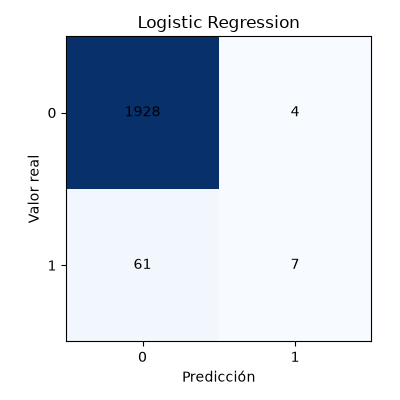

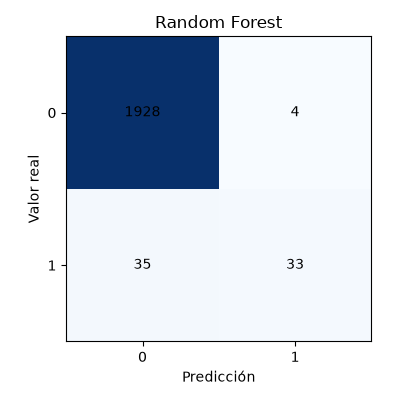

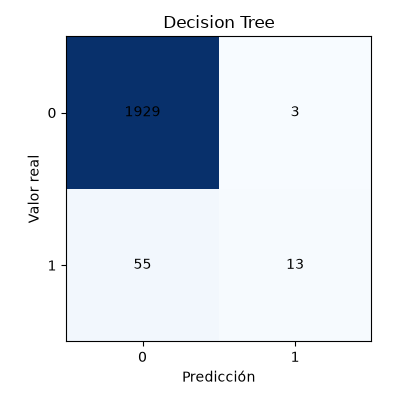

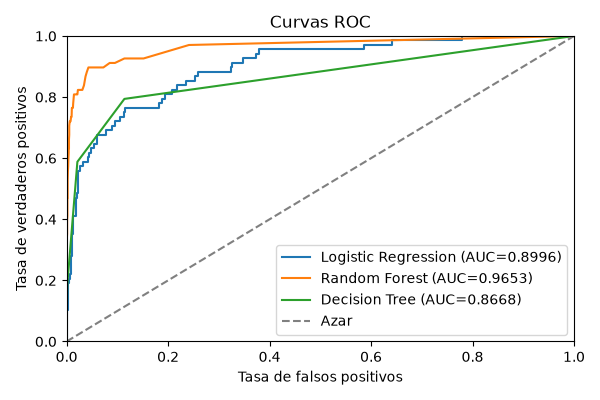

In [8]:
from agrofail.metrics import evaluate_model
from agrofail.report import plot_model_metrics

results = [evaluate_model(model, test.drop(target), test[target]) for model in models]
pprint([{k: v for k, v in vars(result).items() if k not in ('fpr', 'tpr')}
        for result in results])
for path in plot_model_metrics(results, figure_dir):
    display(Image(filename=str(path)))

## 9. Comparación de modelos

Se ordenan por F1 descendente, luego ROC-AUC y accuracy descendentes; los empates exactos se resuelven por nombre ascendente. F1 tiene prioridad ante el desbalance porque combina detección de fallas y fiabilidad de alarmas. Accuracy por sí sola favorece a la clase mayoritaria; ROC-AUC complementa la discriminación pero no establece un costo operativo ni un umbral óptimo. La tabla HTML incluye todas las filas y columnas.

In [9]:
from dataclasses import asdict

from agrofail.compare import choose_model, compare_models

table = compare_models(results)
comparison = pl.DataFrame([{'rank': i, **asdict(row)}
                           for i, row in enumerate(table.rows, 1)])
with pl.Config(tbl_rows=-1, tbl_cols=-1):
    display(comparison)

rank,name,accuracy,precision,recall,f1,roc_auc,tn,fp,fn,tp
i64,str,f64,f64,f64,f64,f64,i64,i64,i64,i64
1,"""Random Forest""",0.9805,0.891892,0.485294,0.628571,0.965283,1928,4,35,33
2,"""Decision Tree""",0.971,0.8125,0.191176,0.309524,0.866798,1929,3,55,13
3,"""Logistic Regression""",0.9675,0.636364,0.102941,0.177215,0.899571,1928,4,61,7


## 9.1. Ajuste de hiperparámetros y estabilidad

GridSearchCV maximiza F1 mediante validación cruzada estratificada de 5 pliegues, con mezcla y semilla 42, solo con entrenamiento. La grilla pequeña explora C con penalización L2 compatible con el solver; 50/100 árboles, profundidad 8/sin límite y hojas de 1/3 registros en el bosque; profundidad 4/8 y hojas de 1/3 en el árbol. No optimiza pesos ni umbrales. Se usan sensores sin escala previa y códigos fijos L=0, M=1, H=2, tratados como categorías, no magnitudes. One-hot y escalado logístico se ajustan dentro de cada pliegue para evitar fuga desde validación. El mejor pipeline se reajusta con todo entrenamiento. Test no participa en la búsqueda.

cv_mean y cv_std son media y desviación estándar poblacional del F1 de los pliegues del candidato ganador. Miden variación interna, no un intervalo de confianza ni validación independiente: los mismos pliegues eligen parámetros. Una desviación pequeña no prueba robustez entre temporadas o establecimientos.

In [10]:
from pprint import pformat

from agrofail.report import _tuning_features
from agrofail.tuning import tune_models

tuning_train = _tuning_features(train_selected)
tuning_test = _tuning_features(test_selected)
tuned = tune_models(tuning_train, train[target],
                    categorical_columns=(len(config.NUMERIC_COLUMNS),))
stability = [{'name': m.name, 'cv_mean': m.cv_mean, 'cv_std': m.cv_std,
              'best_params': m.best_params} for m in tuned]
stability_table = pl.DataFrame([
    {**row, 'best_params': pformat(row['best_params'])} for row in stability])
with pl.Config(tbl_rows=-1, tbl_cols=-1, fmt_str_lengths=200):
    display(stability_table)
pprint(stability)

name,cv_mean,cv_std,best_params
str,f64,f64,str
"""Logistic Regression""",0.330359,0.054611,"""{'classifier__C': 10.0, 'classifier__penalty': 'l2'}"""
"""Random Forest""",0.626073,0.039604,"""{'classifier__max_depth': None, 'classifier__min_samples_leaf': 1, 'classifier__n_estimators': 100}"""
"""Decision Tree""",0.709613,0.043618,"""{'classifier__max_depth': 8, 'classifier__min_samples_leaf': 3}"""


[{'name': 'Logistic Regression',
  'cv_mean': 0.330359109486047,
  'cv_std': 0.054611367673206936,
  'best_params': {'classifier__C': 10.0, 'classifier__penalty': 'l2'}},
 {'name': 'Random Forest',
  'cv_mean': 0.6260725216193835,
  'cv_std': 0.039603901448911204,
  'best_params': {'classifier__max_depth': None,
                  'classifier__min_samples_leaf': 1,
                  'classifier__n_estimators': 100}},
 {'name': 'Decision Tree',
  'cv_mean': 0.7096128065382077,
  'cv_std': 0.043617769569563765,
  'best_params': {'classifier__max_depth': 8,
                  'classifier__min_samples_leaf': 3}}]

## 9.2. Comparación ajustada en prueba

Se evalúan los pipelines ajustados con el mismo test y la misma regla F1, ROC-AUC y accuracy. No se garantiza mejora frente a las líneas base. La elección pasa de **Random Forest** a **Decision Tree** (puede conservar la misma familia). La elección final se basa en esta tabla.

In [11]:
tuned_results = [evaluate_model(model, tuning_test, test[target]) for model in tuned]
table = compare_models(tuned_results)
comparison = pl.DataFrame([{'rank': i, **asdict(row)}
                           for i, row in enumerate(table.rows, 1)])
display(comparison)

rank,name,accuracy,precision,recall,f1,roc_auc,tn,fp,fn,tp
i64,str,f64,f64,f64,f64,f64,i64,i64,i64,i64
1,"""Decision Tree""",0.985,0.839286,0.691176,0.758065,0.8877,1923,9,21,47
2,"""Random Forest""",0.982,0.9,0.529412,0.666667,0.965283,1928,4,32,36
3,"""Logistic Regression""",0.9675,0.615385,0.117647,0.197531,0.899791,1927,5,60,8


## 10. Elección justificada y reflexión técnica

Se propone **Decision Tree** ajustado como modelo provisional, no como sistema listo para producción.

- **Rendimiento:** F1=0.7581, ROC-AUC=0.8877, accuracy=0.9850, precisión=0.8393 y recall=0.6912; ocupa el primer puesto bajo la regla explícita.
- **Tipos de error:** 21 falsos negativos y 9 falsos positivos. Una falla omitida puede causar una parada inesperada; una falsa alarma puede generar inspección innecesaria. No se dispone de costos medidos: F1 es un compromiso inicial, no una demostración de menor costo.
- **Estabilidad:** F1 medio de validación cruzada=0.7096, desviación estándar=0.0436 en 5 pliegues de entrenamiento. Esta variación medida no demuestra robustez temporal ni agrícola.
- **Interpretabilidad:** su profundidad máxima ajustada de 8 permite inspeccionar reglas, con complejidad mayor si aumenta la profundidad. Esta limitación debe considerarse al explicar alarmas al equipo de mantenimiento.
- **Adecuación al dominio:** sensores y desgaste son relevantes para el mantenimiento, pero los datos sintéticos industriales no validan uso agrícola.

La comparación usa test para elegir entre modelos: por ello deja de ser una auditoría final independiente del elegido. Se necesita validación posterior con datos nuevos. Se ajustaron hiperparámetros en entrenamiento, no umbrales.

In [12]:
choice = choose_model(table)
selected = next(m for m in tuned if m.name == choice.name)
choice_data = asdict(choice)
choice_data['rationale']['stability'] = (
    f'Training CV F1 mean={selected.cv_mean:.4f}, std={selected.cv_std:.4f}; '
    'selected on these folds, not an independent audit or domain validation.')
if choice.name == 'Decision Tree':
    choice_data['rationale']['interpretability'] = (
        f"The tuned tree has maximum depth {selected.best_params['classifier__max_depth']}; "
        'inspect its rules before claiming simplicity.')
pprint(choice_data)

{'name': 'Decision Tree',
 'rationale': {'performance': 'Ranked first by F1 descending, ROC-AUC '
                              'descending, accuracy descending, name '
                              'ascending; F1=0.7581, ROC-AUC=0.8877, '
                              'accuracy=0.9850.',
               'error_types': 'False negatives=21; false positives=9. Missed '
                              'failures can cause unplanned downtime; false '
                              'alarms cause unnecessary inspections. '
                              'Operational costs are not measured; F1 is a '
                              'provisional tradeoff.',
               'stability': 'Training CV F1 mean=0.7096, std=0.0436; selected '
                            'on these folds, not an independent audit or '
                            'domain validation.',
               'interpretability': 'The tuned tree has maximum depth 8; '
                                   'inspect its rules before claiming '

## 11. Hallazgos y recomendaciones

La evaluación incluye 2000 registros y 68 fallas (3.40%). El modelo ajustado elegido detecta 47 fallas y omite 21; genera 9 falsas alarmas. Estos conteos permiten discutir el mantenimiento más directamente que accuracy aislada.

Se recomienda recopilar registros reales de maquinaria agrícola con fechas, equipos, condiciones de operación y fallas verificadas; validar por tiempo y por equipo para evitar fugas y comprobar estabilidad. Antes de desplegar, cuantificar costos de inspección y parada, acordar una sensibilidad mínima y evaluar umbrales en validación independiente. Supervisar desbalance, calibración y deriva de sensores; mantener revisión humana de las alertas. La síntesis didáctica es viable, pero no prueba eficacia en campo ni causalidad. Los próximos experimentos no se presentan como resultados ya obtenidos.

In [13]:
pprint({'evaluated_rows': test.height, 'failures': int(test[target].sum()),
        'selected_model': choice.name})

{'evaluated_rows': 2000, 'failures': 68, 'selected_model': 'Decision Tree'}

## Anexo: fuente y referencias

Fuente: [AI4I 2020 en UCI](https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset).

Descarga oficial: https://archive.ics.uci.edu/static/public/601/ai4i+2020+predictive+maintenance+dataset.zip.

Licencia: [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).

Referencias: Matzka, S. (2020). AI4I 2020 Predictive Maintenance Dataset. UCI Machine Learning Repository. https://doi.org/10.24432/C5HS5C.

Son datos sintéticos industriales, no mediciones de maquinaria agrícola; la analogía no sustituye validación con datos del sector.

In [14]:
provenance = {'source_page': 'https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset',
 'download_url': 'https://archive.ics.uci.edu/static/public/601/ai4i+2020+predictive+maintenance+dataset.zip',
 'license': 'CC BY 4.0',
 'citation': 'Matzka, S. (2020). AI4I 2020 Predictive Maintenance Dataset. UCI '
             'Machine Learning Repository. https://doi.org/10.24432/C5HS5C'}
pprint(provenance)

{'source_page': 'https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset',
 'download_url': 'https://archive.ics.uci.edu/static/public/601/ai4i+2020+predictive+maintenance+dataset.zip',
 'license': 'CC BY 4.0',
 'citation': 'Matzka, S. (2020). AI4I 2020 Predictive Maintenance Dataset. UCI '
             'Machine Learning Repository. https://doi.org/10.24432/C5HS5C'}